# Phase 0: Exploratory Data Analysis

Look at the cleaned data: class balance, image sizes, lesion sizes and positions, sample images with masks, and markers.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)  
**Output:** plots and tables in this notebook only, no files saved

## 1. Imports and load the manifest

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from skimage.measure import label, regionprops

In [2]:
DATA_DIR = Path('data')
CLASS_ORDER = ['normal', 'benign', 'malignant']
SPLIT_ORDER = ['train', 'val', 'test']

MIN_LESION_PIXELS = 50    # same value as 00_clean_data: smaller regions are annotation noise
HEATMAP_SIZE = 128        # masks are shrunk to this size to build the position heatmap
RANDOM_STATE = 42

df = pd.read_csv(DATA_DIR / 'manifest.csv')
print(f'{len(df)} images in the manifest')
df.head()

669 images in the manifest


,image_path,mask_paths,label,width,height,n_lesions,has_markers,duplicate_group,lookalike_group,split,fold
0,normal/normal (10).png,normal/normal (10)_mask.png,normal,501,485,0,False,1,1,train,2
1,normal/normal (100).png,normal/normal (100)_mask.png,normal,690,574,0,False,2,2,train,1
2,normal/normal (101).png,normal/normal (101)_mask.png,normal,678,572,0,False,3,3,val,0
3,normal/normal (102).png,normal/normal (102)_mask.png,normal,770,576,0,False,4,4,train,4
4,normal/normal (103).png,normal/normal (103)_mask.png,normal,772,574,0,False,5,5,test,-1


## 2. Class balance

How many images each class has, overall and in each split. The split should keep the same ratio everywhere.

In [3]:
pd.crosstab(df['label'], df['split'], margins=True).loc[CLASS_ORDER + ['All'], SPLIT_ORDER + ['All']]

split,train,val,test,All
label,,,,
normal,72,18,17,107
benign,246,61,57,364
malignant,136,34,28,198
All,454,113,102,669


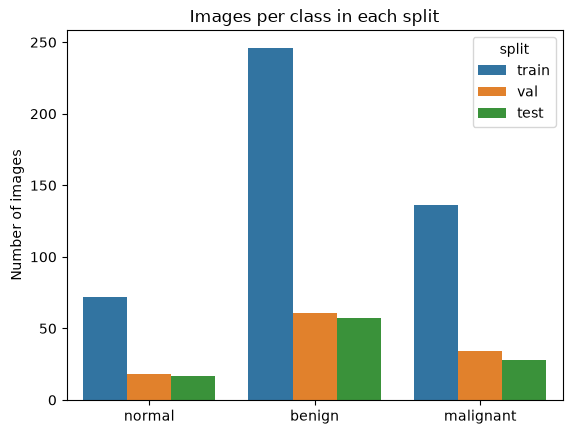

In [4]:
sns.countplot(data=df, x='label', hue='split', order=CLASS_ORDER, hue_order=SPLIT_ORDER)
plt.title('Images per class in each split')
plt.xlabel('')
plt.ylabel('Number of images')
plt.show()

## 3. Image sizes

The scans come in many different sizes, which is why every model resizes them to the same size first.

In [5]:
df.groupby('label')[['width', 'height']].describe().loc[CLASS_ORDER].round(0)

width                                                   height  \
           count   mean    std    min    25%    50%    75%     max  count   
label                                                                       
normal     107.0  657.0  127.0  392.0  556.0  619.0  765.0   948.0  107.0   
benign     364.0  623.0  116.0  315.0  555.0  566.0  731.0  1028.0  364.0   
malignant  198.0  601.0  124.0  190.0  552.0  565.0  653.0  1048.0  198.0   

                                                           
            mean   std    min    25%    50%    75%    max  
label                                                      
normal     536.0  86.0  310.0  470.0  494.0  585.0  712.0  
benign     503.0  78.0  324.0  465.0  473.0  576.0  719.0  
malignant  495.0  61.0  332.0  463.0  474.0  556.0  677.0

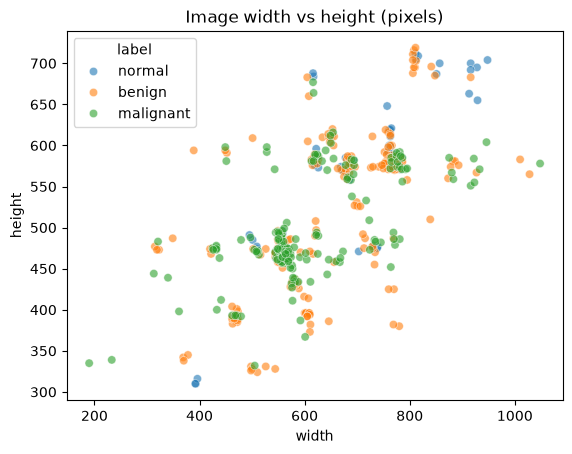

In [6]:
sns.scatterplot(data=df, x='width', y='height', hue='label', hue_order=CLASS_ORDER, alpha=0.6)
plt.title('Image width vs height (pixels)')
plt.show()

## 4. Lesions per image

In [7]:
pd.crosstab(df['label'], df['n_lesions']).loc[CLASS_ORDER]

n_lesions,0,1,2
label,,,
normal,107,0,0
benign,0,351,13
malignant,0,197,1


## 5. Lesion size and position

For every benign and malignant image, we merge its masks, split them into separate lesions and record each lesion's:
- **size** as % of the image area, so images of different sizes can be compared
- **centre** as a fraction of the image width and height (0 = left / top, 1 = right / bottom)

We also add up all the masks of each class to make a **heatmap** of where lesions usually appear.

In [8]:
def load_mask(mask_paths):
    """Merge all masks of an image into one True/False array (True = lesion)."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return np.any(masks, axis=0)


lesion_rows = []
heatmaps = {'benign': np.zeros((HEATMAP_SIZE, HEATMAP_SIZE)),
            'malignant': np.zeros((HEATMAP_SIZE, HEATMAP_SIZE))}

for row in df[df['label'] != 'normal'].itertuples():
    mask = load_mask(row.mask_paths)
    height, width = mask.shape

    # One row per lesion
    for region in regionprops(label(mask, connectivity=2)):
        if region.area < MIN_LESION_PIXELS:
            continue                                         # skip tiny specks
        centre_y, centre_x = region.centroid
        lesion_rows.append({
            'image_path': row.image_path,
            'label': row.label,
            'area_pct': region.area / mask.size * 100,       # lesion area as % of the image
            'centre_x': centre_x / width,                    # 0 = left edge, 1 = right edge
            'centre_y': centre_y / height,                   # 0 = top (skin), 1 = bottom (deep)
        })

    # Add this mask to its class heatmap (shrunk to the same size for every image)
    small = Image.fromarray(mask.astype(np.uint8) * 255).resize((HEATMAP_SIZE, HEATMAP_SIZE))
    heatmaps[row.label] += np.array(small) / 255

lesions = pd.DataFrame(lesion_rows)
print(f'{len(lesions)} lesions measured')
lesions.head()

576 lesions measured


,image_path,label,area_pct,centre_x,centre_y
0,benign/benign (1).png,benign,0.371739,0.558836,0.311802
1,benign/benign (10).png,benign,8.238666,0.197249,0.286120
2,benign/benign (100).png,benign,1.911912,0.192830,0.279091
3,benign/benign (100).png,benign,4.640690,0.783616,0.375313
4,benign/benign (101).png,benign,1.564782,0.862718,0.415391


### Lesion size by class

In [9]:
lesions.groupby('label')['area_pct'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
benign,377.0,6.45,8.24,0.28,1.41,3.11,8.08,51.30
malignant,199.0,14.85,10.91,0.21,6.02,12.14,20.95,56.29


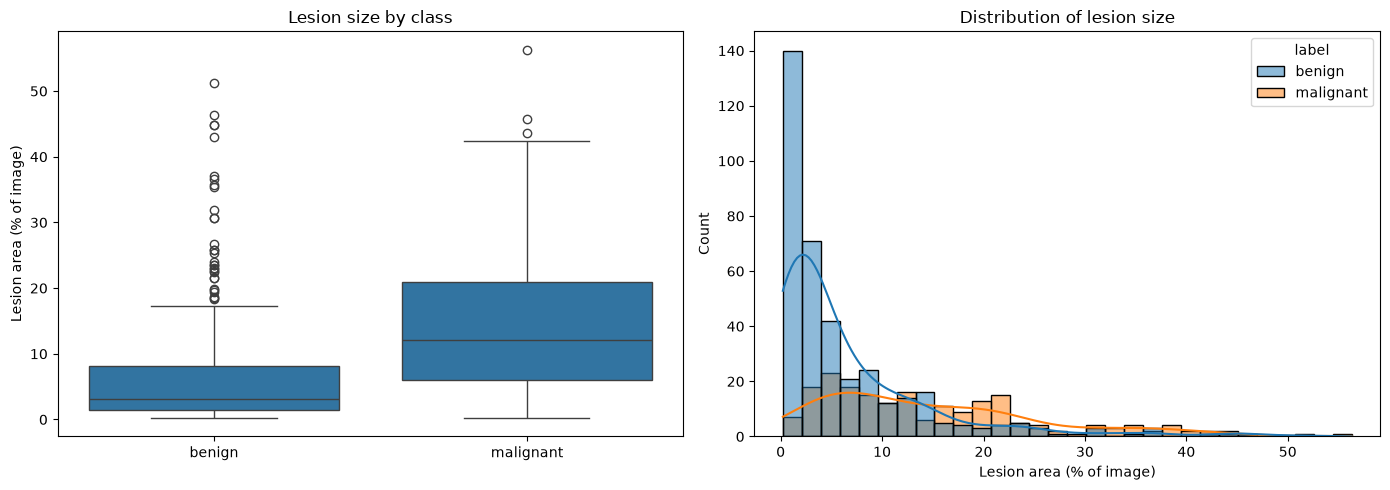

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=lesions, x='label', y='area_pct', order=['benign', 'malignant'], ax=axes[0])
axes[0].set_title('Lesion size by class')
axes[0].set_xlabel('')
axes[0].set_ylabel('Lesion area (% of image)')

sns.histplot(data=lesions, x='area_pct', hue='label', hue_order=['benign', 'malignant'],
             bins=30, kde=True, ax=axes[1])
axes[1].set_title('Distribution of lesion size')
axes[1].set_xlabel('Lesion area (% of image)')

plt.tight_layout()
plt.show()

### Lesion position

The y-axis is flipped so the top of the plot is the top of the scan, which is the skin.

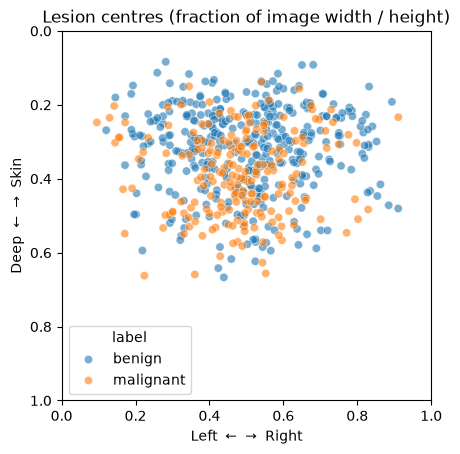

In [11]:
sns.scatterplot(data=lesions, x='centre_x', y='centre_y', hue='label',
                hue_order=['benign', 'malignant'], alpha=0.6)
plt.xlim(0, 1)
plt.ylim(1, 0)                                   # flip: 0 (skin) at the top
plt.gca().set_aspect('equal')
plt.title('Lesion centres (fraction of image width / height)')
plt.xlabel('Left  ←  →  Right')
plt.ylabel('Deep  ←  →  Skin')
plt.show()

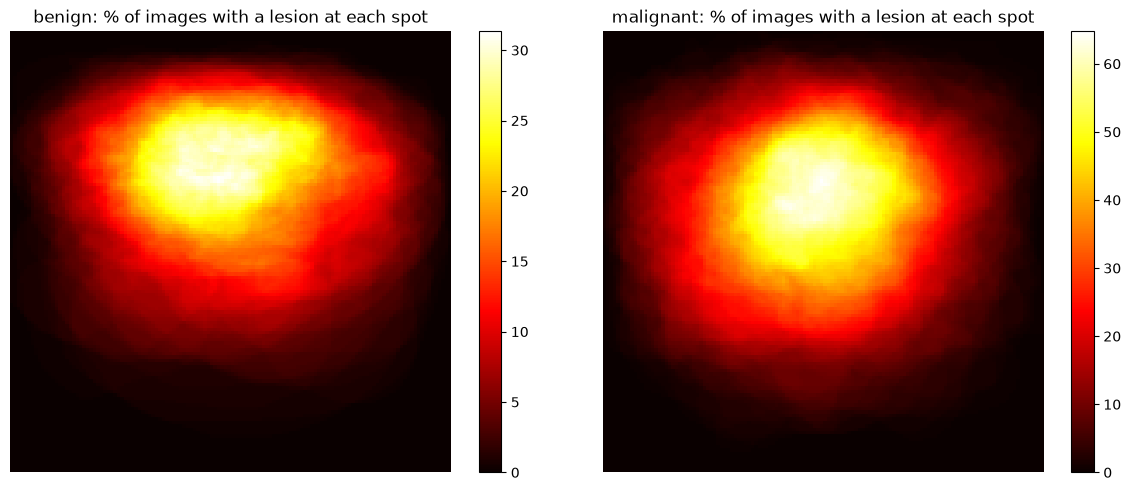

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, class_name in zip(axes, ['benign', 'malignant']):
    n_images = (df['label'] == class_name).sum()
    image = ax.imshow(heatmaps[class_name] / n_images * 100, cmap='hot', vmin=0)
    ax.set_title(f'{class_name}: % of images with a lesion at each spot')
    ax.axis('off')
    fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 6. Sample images with masks

Five random scans per class, with the lesion masks shown in colour. Normal scans have no mask.

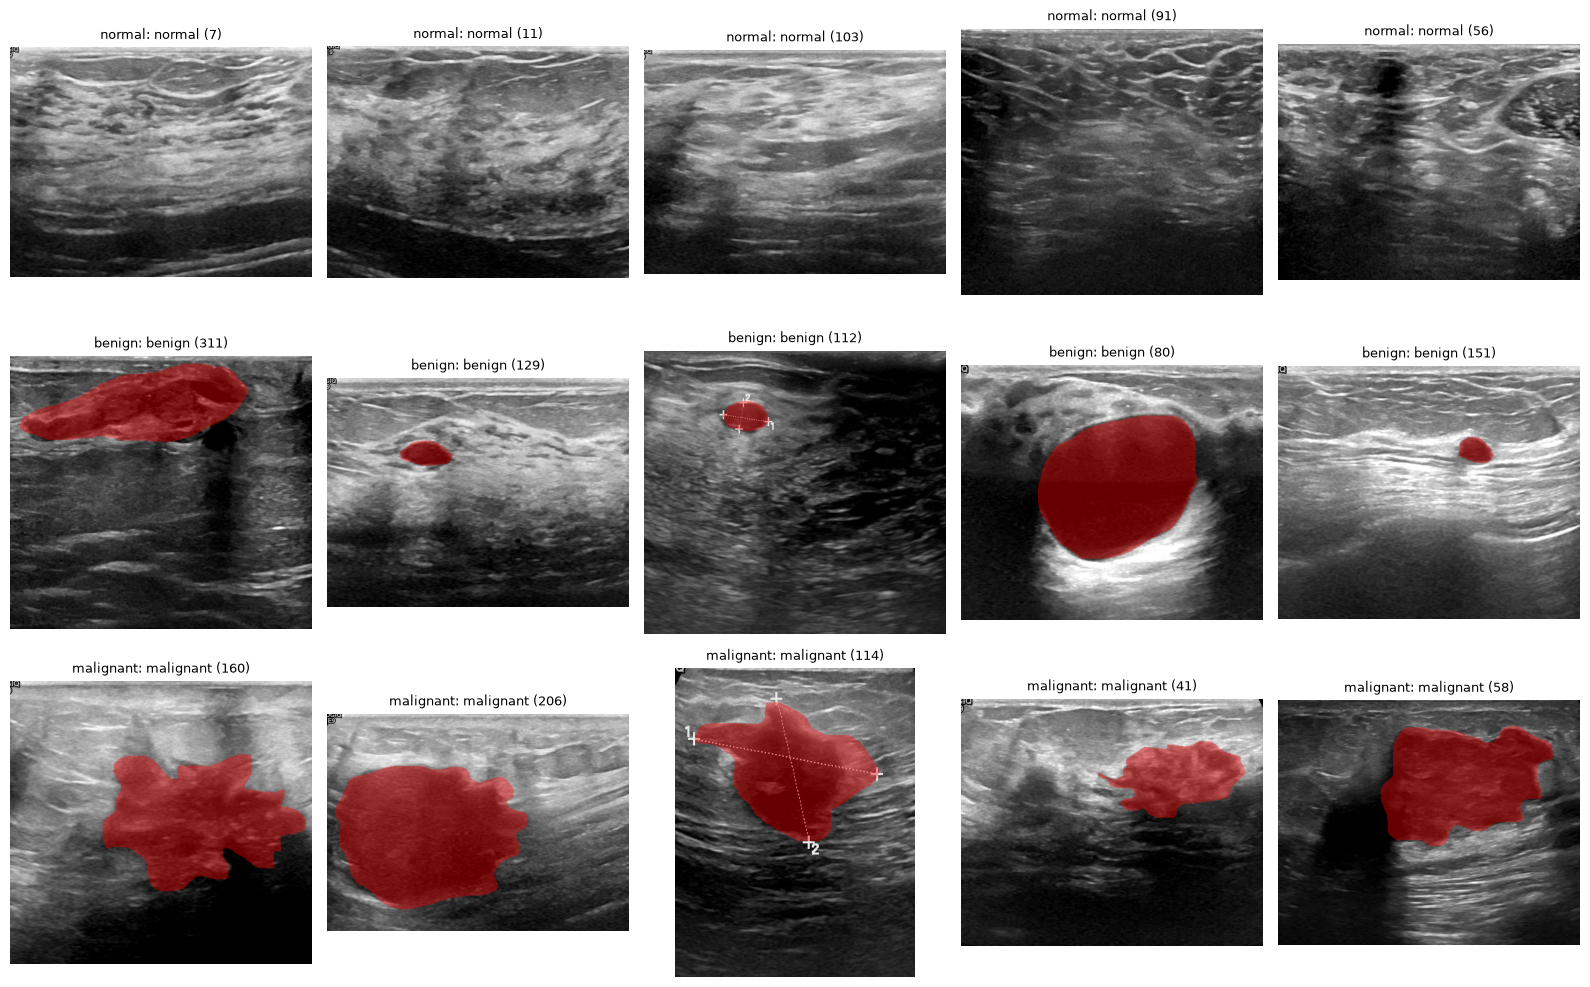

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for axes_row, class_name in zip(axes, CLASS_ORDER):
    samples = df[df['label'] == class_name].sample(5, random_state=RANDOM_STATE)
    for ax, row in zip(axes_row, samples.itertuples()):
        image = np.array(Image.open(DATA_DIR / row.image_path).convert('L'))
        mask = load_mask(row.mask_paths)

        ax.imshow(image, cmap='gray')
        ax.imshow(np.ma.masked_where(~mask, mask.astype(float)), cmap='autumn', alpha=0.4)   # colour only the lesion
        ax.set_title(f'{class_name}: {Path(row.image_path).stem}', fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()

## 7. Markers by class

If one class has many more markers (calipers, text, coloured marks) than the others, a model could learn to spot the markers instead of the tissue. This is the **shortcut risk** we'll test for later.

label
normal       44.9
benign       62.1
malignant    61.6


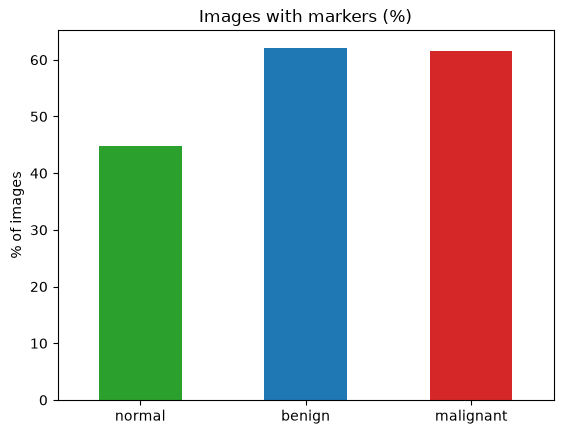

In [14]:
marker_pct = (df.groupby('label')['has_markers'].mean() * 100).loc[CLASS_ORDER]   # % of images with markers
print(marker_pct.round(1).to_string())

marker_pct.plot(kind='bar', color=['tab:green', 'tab:blue', 'tab:red'])
plt.title('Images with markers (%)')
plt.xlabel('')
plt.ylabel('% of images')
plt.xticks(rotation=0)
plt.show()